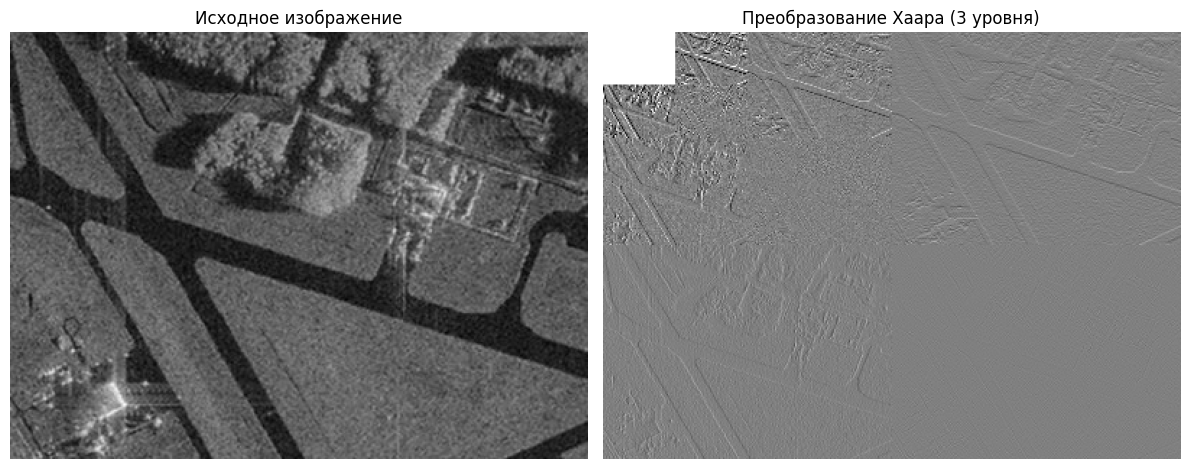

In [3]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

img = cv.imread('sar_1.jpg', cv.IMREAD_GRAYSCALE)
h, w = img.shape
h = h - h % 8
w = w - w % 8
img = np.float32(img[:h, :w])

def haar_forward(image):
    h, w = image.shape
    h2, w2 = h // 2, w // 2
    a = image[0::2, 0::2]
    b = image[0::2, 1::2]
    c = image[1::2, 0::2]
    d = image[1::2, 1::2]
    ll = (a + b + c + d) / 2.0
    lh = (a + b - c - d) / 2.0
    hl = (a - b + c - d) / 2.0
    hh = (a - b - c + d) / 2.0
    result = np.zeros_like(image)
    result[:h2, :w2] = ll
    result[:h2, w2:] = lh
    result[h2:, :w2] = hl
    result[h2:, w2:] = hh
    return result

level1 = haar_forward(img)
h, w = img.shape
h2, w2 = h // 2, w // 2
level2 = level1.copy()
level2[:h2, :w2] = haar_forward(level1[:h2, :w2])
h4, w4 = h2 // 2, w2 // 2
level3 = level2.copy()
level3[:h4, :w4] = haar_forward(level2[:h4, :w4])

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(np.clip(level3 + 128, 0, 255), cmap='gray')
plt.title('Преобразование Хаара (3 уровня)')
plt.axis('off')
plt.tight_layout()
plt.show()